In [ ]:
import copy
import time
import random
from typing import Dict, List, Tuple

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as ticker
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Fundamental Electromagnetic Constants
Z0 = 377.0          # Free space impedance (Ohms)
C_LIGHT = 3.0e8     # Speed of light in vacuum (m/s)

# Frequency Sweep Configuration (X-band / C-band radar absorber range: 2 to 12 GHz)
FREQ_GHZ = np.linspace(2.0, 12.0, 500)
FREQ_HZ = FREQ_GHZ * 1e9
DF_GHZ = float(FREQ_GHZ[1] - FREQ_GHZ[0])

# Bounds for Theoretical Bulk Material 
MATERIAL_BOUNDS = {
    'mu_real':  (-20.0, 20.0),    # mu_r'
    'mu_imag':  (0.001, 0.09),    # mu_r''
    'eps_real': (1.5, 10.0),      # eps_r'
    'eps_imag': (0.001, 0.09),    # eps_r''
    'd_mat_mm': (1.5, 8.0)        # Material thickness d (mm)
}

# Search Bounds for Square Loop FSS Absorber (Page 2 & 3 of Notes)
# Parameters: (p, d, s, h, eps_r, Rs) -> g = p - d is derived automatically
FSS_SEARCH_BOUNDS = {
    'p_mm':   (8.0, 22.0),    # Periodicity / Unit cell size p (mm)
    'd_mm':   (4.0, 20.0),    # Outer loop side length d (mm)
    's_mm':   (0.3, 4.0),     # Conductive loop strip width s (mm)
    'h_mm':   (1.5, 8.0),     # Dielectric substrate thickness h (mm)
    'eps_r':  (1.5, 10.0),    # Substrate real permittivity eps_r'
    'Rs_ohm': (0.5, 15.0)     # FSS sheet resistance Rs (Ohms/sq) for resistive loading
}

FSS_PARAM_KEYS = ['p_mm', 'd_mm', 's_mm', 'h_mm', 'eps_r', 'Rs_ohm']

print(">> Cell 1 Initialized: Constants, Frequency Grid (2-12 GHz), and Bounds Locked.")

>> Cell 1 Initialized: Constants, Frequency Grid (2-12 GHz), and Bounds Locked.


In [ ]:

class BulkMaterialPhysics:
    """Computes surface impedance and reflection coefficient of a conductor-backed slab."""

    @staticmethod
    def compute_impedance(
        freqs_hz: np.ndarray,
        mu_real: float,
        mu_imag: float,
        eps_real: float,
        eps_imag: float,
        d_mat_mm: float
    ) -> np.ndarray:
        """
        Z_material = Z0 * sqrt(mu_r / eps_r) * tanh(j * (2*pi*f*d / c) * sqrt(mu_r * eps_r))
        """
        d_m = d_mat_mm * 1e-3
        mu_r = mu_real - 1j * mu_imag
        eps_r = eps_real - 1j * eps_imag

        # Wave impedance and propagation argument inside the bulk material
        eta_rel = np.sqrt(mu_r / eps_r)
        prop_arg = 1j * (2.0 * np.pi * freqs_hz * d_m / C_LIGHT) * np.sqrt(mu_r * eps_r)

        Z_mat = Z0 * eta_rel * np.tanh(prop_arg)
        return Z_mat

    @staticmethod
    def compute_reflection_db(Z_in: np.ndarray) -> np.ndarray:
        """
        Rc = 20 * log10( |(Z_in - Z0) / (Z_in + Z0)| )
        """
        gamma = (Z_in - Z0) / (Z_in + Z0)
        rc_mag = np.clip(np.abs(gamma), 1e-12, None)
        return 20.0 * np.log10(rc_mag)


# Define Reference Target Bulk Material Profiles (within the Page 1 bounds)
# Each profile represents a distinct target resonance frequency to test our optimizer
TARGET_MATERIAL_BENCHMARKS = {
    'Target_A (5.5 GHz)': {
        'mu_real': 3.20, 'mu_imag': 0.085, 'eps_real': 4.40, 'eps_imag': 0.085, 'd_mat_mm': 3.65
    },
    'Target_B (7.0 GHz)': {
        'mu_real': 2.50, 'mu_imag': 0.080, 'eps_real': 3.80, 'eps_imag': 0.080, 'd_mat_mm': 3.50
    },
    'Target_C (8.5 GHz)': {
        'mu_real': 2.10, 'mu_imag': 0.075, 'eps_real': 3.20, 'eps_imag': 0.075, 'd_mat_mm': 3.40
    }
}

# Precompute and plot the baseline Target Material Reflection Curve (Target_B at 7.0 GHz)
ACTIVE_TARGET_NAME = 'Target_B (7.0 GHz)'
ACTIVE_MATERIAL_PARAMS = TARGET_MATERIAL_BENCHMARKS[ACTIVE_TARGET_NAME]

Z_mat_target = BulkMaterialPhysics.compute_impedance(FREQ_HZ, **ACTIVE_MATERIAL_PARAMS)
Rc_mat_target = BulkMaterialPhysics.compute_reflection_db(Z_mat_target)

print(f">> Cell 2 Ready: Target Bulk Material ({ACTIVE_TARGET_NAME}) Computed.")
print(f"   Peak Material Absorption: {np.min(Rc_mat_target):.2f} dB at {FREQ_GHZ[np.argmin(Rc_mat_target)]:.2f} GHz")

>> Cell 2 Ready: Target Bulk Material (Target_B (7.0 GHz)) Computed.
   Peak Material Absorption: -1.05 dB at 12.00 GHz


In [3]:


class SquareLoopFSSPhysics:
    """
    Analytical Equivalent Circuit Model for a Square Loop FSS Absorber
    based on Marcuvitz waveguide grating functions (Page 1 & Page 2 of Notes).
    """

    @staticmethod
    def check_constraints(params: Dict[str, float]) -> Tuple[bool, float]:
        """
        Enforces Page 3 Geometric Constraints:
          1) p > d  (Gap g = p - d must be strictly positive, min 0.4 mm for manufacturability)
          2) d > 2s (Inner loop opening d - 2s must be strictly positive, min 0.6 mm)
        Returns (is_valid, penalty_score).
        """
        p = params['p_mm']
        d = params['d_mm']
        s = params['s_mm']

        gap_g = p - d
        inner_hole = d - 2.0 * s

        penalty = 0.0
        if gap_g < 0.4:
            penalty += (0.4 - gap_g) * 50.0
        if inner_hole < 0.6:
            penalty += (0.6 - inner_hole) * 50.0

        is_valid = (penalty == 0.0)
        return is_valid, penalty

    @staticmethod
    def grating_function_F(p_m: float, w_m: float, lam_m: np.ndarray) -> np.ndarray:
        """
        Marcuvitz Grating Function F(p, w, lambda) from Page 2:
          F(w) = (p / lambda) * [ ln( csc(pi * w / (2 * p)) ) + G_corr ]
        """
        ratio = np.clip(w_m / (2.0 * p_m), 1e-4, 0.499)
        sin_val = np.sin(np.pi * ratio)
        csc_val = 1.0 / np.clip(sin_val, 1e-9, None)

        # Fundamental logarithmic grating term
        ln_term = np.log(csc_val)

        # First-order higher-mode correction term (Langley & Parker)
        cos_val = np.cos(np.pi * ratio)
        beta = sin_val ** 2
        A_plus = 1.0 / np.sqrt(np.maximum(1.0 - (p_m / lam_m) ** 2, 1e-6)) - 1.0
        G_corr = (0.5 * ((1.0 - beta) ** 2) * (2.0 * (1.0 - (beta ** 2) / 4.0) * A_plus)) / (
            1.0 + (1.0 - (beta ** 2) / 2.0) * A_plus
        )

        return (p_m / lam_m) * (ln_term + G_corr)

    @staticmethod
    def simulate_fss_absorber(
        freqs_hz: np.ndarray,
        params: Dict[str, float]
    ) -> Tuple[np.ndarray, np.ndarray, Dict[str, np.ndarray]]:
        """
        Computes Z_fss_absorber and Rc_fss_absorber (in dB) across the frequency band.
        """
        p_m = params['p_mm'] * 1e-3
        d_m = params['d_mm'] * 1e-3
        s_m = params['s_mm'] * 1e-3
        h_m = params['h_mm'] * 1e-3
        eps_r = params['eps_r']
        Rs = params['Rs_ohm']

        # Gap between adjacent square loops: g = p - d
        g_m = max(p_m - d_m, 1e-5)

        lam_m = C_LIGHT / freqs_hz
        beta_0 = (2.0 * np.pi * freqs_hz) / C_LIGHT

        # 1. Grounded Dielectric Substrate Impedance (Page 1):
        #    Z_sub = j * (Z0 / sqrt(eps_r)) * tan(beta_0 * h * sqrt(eps_r))
        eps_complex = eps_r * (1.0 - 1j * 0.002)  # Slight dielectric loss tangent for numerical stability
        Z_sub = 1j * (Z0 / np.sqrt(eps_complex)) * np.tan(beta_0 * h_m * np.sqrt(eps_complex))

        # 2. Inductance and Capacitance Reactances (Page 2):
        #    wL = Z0 * (d / p) * F(2s)
        #    wC = (4 / Z0) * (d / p) * F(g) * ((eps_r + 1) / 2)
        F_2s = SquareLoopFSSPhysics.grating_function_F(p_m, 2.0 * s_m, lam_m)
        F_g = SquareLoopFSSPhysics.grating_function_F(p_m, g_m, lam_m)

        wL = Z0 * (d_m / p_m) * F_2s
        wC = (4.0 / Z0) * (d_m / p_m) * F_g * ((eps_r + 1.0) / 2.0)
        wC = np.clip(wC, 1e-12, None)

        # 3. FSS Sheet Impedance (Page 1):
        #    Z_f = Rs * (d / 2s) + j * (wL - 1 / wC)
        R_loop = Rs * (d_m / (2.0 * s_m))
        X_loop = wL - (1.0 / wC)
        Z_f = R_loop + 1j * X_loop

        # 4. Total Parallel FSS Absorber Impedance (Page 1):
        #    Z_fss_absorber = (Z_f * Z_sub) / (Z_f + Z_sub)
        Z_fss_abs = (Z_f * Z_sub) / (Z_f + Z_sub)

        # 5. Reflection Coefficient in dB (Page 2):
        #    Rc_fss = 20 * log10( |(Z_fss - Z0) / (Z_fss + Z0)| )
        Rc_fss_db = BulkMaterialPhysics.compute_reflection_db(Z_fss_abs)

        aux = {'Z_f': Z_f, 'Z_sub': Z_sub, 'wL': wL, 'wC': wC}
        return Z_fss_abs, Rc_fss_db, aux

    @staticmethod
    def evaluate_performance_metrics(
        freqs_ghz: np.ndarray,
        Rc_fss_db: np.ndarray,
        Z_fss_abs: np.ndarray,
        Z_mat_ref: np.ndarray
    ) -> Dict[str, float]:
        """
        Extracts the exact metrics required on Page 2 & Page 3:
          - Minimum Reflection Coefficient (dB)
          - Resonance Frequency f_res (GHz)
          - -20 dB Absorption Bandwidth (GHz and Fractional %)
          - Normalized Impedance Match Error |Z_material - Z_fss| / Z0
        """
        min_rc_db = float(np.min(Rc_fss_db))
        res_idx = int(np.argmin(Rc_fss_db))
        f_res_ghz = float(freqs_ghz[res_idx])

        # Bandwidth below -20 dB
        below_20_mask = Rc_fss_db <= -20.0
        bw_20db_ghz = float(np.sum(below_20_mask) * (freqs_ghz[1] - freqs_ghz[0]))
        frac_bw_pct = (bw_20db_ghz / f_res_ghz) * 100.0 if f_res_ghz > 0 else 0.0

        # Impedance mismatch near the target resonance region
        target_res_idx = int(np.argmin(BulkMaterialPhysics.compute_reflection_db(Z_mat_ref)))
        window = slice(max(0, target_res_idx - 40), min(len(freqs_ghz), target_res_idx + 40))
        z_err_norm = float(np.mean(np.abs(Z_fss_abs[window] - Z_mat_ref[window])) / Z0)

        return {
            'min_rc_db': min_rc_db,
            'f_res_ghz': f_res_ghz,
            'bw_20db_ghz': bw_20db_ghz,
            'frac_bw_pct': frac_bw_pct,
            'z_err_norm': z_err_norm
        }

print(">> Cell 3 Ready: Square Loop FSS Physics Engine & Constraint Evaluator Compiled.")

>> Cell 3 Ready: Square Loop FSS Physics Engine & Constraint Evaluator Compiled.


In [4]:


def build_fss_physics_objective(
    freqs_ghz: np.ndarray,
    freqs_hz: np.ndarray,
    Z_mat_target: np.ndarray,
    Rc_mat_target: np.ndarray
):
    """
    Pure physics objective function with ZERO hardcoded dimension targets.
    Directly optimizes:
      1) Z_material == Z_fss_absorber (Impedance & resonance alignment)
      2) min(Rc_fss) << -20 dB (Deep reflection null)
      3) max Bandwidth below -20 dB
      4) Strict satisfaction of p > d and d > 2s
    """
    target_f_res = float(freqs_ghz[np.argmin(Rc_mat_target)])

    def evaluate_fitness(params: Dict[str, float]) -> Tuple[float, Dict[str, float]]:
        is_valid, geom_penalty = SquareLoopFSSPhysics.check_constraints(params)
        if not is_valid:
            # Heavy penalty if geometric constraints p > d or d > 2s are violated
            return -100.0 - geom_penalty, {
                'min_rc_db': 0.0, 'f_res_ghz': 0.0, 'bw_20db_ghz': 0.0,
                'frac_bw_pct': 0.0, 'z_err_norm': 10.0, 'valid': False
            }

        Z_fss, Rc_fss, _ = SquareLoopFSSPhysics.simulate_fss_absorber(freqs_hz, params)
        metrics = SquareLoopFSSPhysics.evaluate_performance_metrics(
            freqs_ghz, Rc_fss, Z_fss, Z_mat_target
        )
        metrics['valid'] = True

        # Term 1: Resonance frequency alignment with target material dip
        freq_align_loss = ((metrics['f_res_ghz'] - target_f_res) / 2.0) ** 2

        # Term 2: Impedance matching loss |Z_fss - Z_material|
        z_match_loss = metrics['z_err_norm'] * 0.5

        # Term 3: Deep reflection minimization below -20 dB (capped at -45 dB to prevent overfitting spikes)
        depth_bonus = max(0.0, -metrics['min_rc_db'] - 20.0) / 20.0
        depth_bonus = min(depth_bonus, 1.25)
        if metrics['min_rc_db'] > -20.0:
            # Penalty if it fails to reach -20 dB
            depth_bonus = -((metrics['min_rc_db'] - (-20.0)) / 10.0) ** 2

        # Term 4: Maximize -20 dB Bandwidth (Primary structural objective on Page 3)
        bw_bonus = metrics['bw_20db_ghz'] * 1.8

        total_score = bw_bonus + depth_bonus - (3.5 * freq_align_loss) - z_match_loss
        return float(total_score), metrics

    return evaluate_fitness


class SquareLoopFSS_PPOEnv:
    """
    Continuous RL Environment for Square Loop FSS Absorber Synthesis.
    Uses a constraint-preserving parameterization so p > d and d > 2s are naturally respected.
    """
    def __init__(self, fitness_fn, max_steps: int = 40):
        self.fitness_fn = fitness_fn
        self.max_steps = max_steps
        self.obs_dim = 8   # 6 normalized parameters + current score + step fraction
        self.act_dim = 6   # Continuous adjustments to [p, d_ratio, s_ratio, h, eps_r, Rs]

        self.best_score = float('-inf')
        self.best_params: Dict[str, float] = {}
        self.best_metrics: Dict[str, float] = {}
        self.history: List[float] = []

        self.reset()

    def _latent_to_physical(self, u: np.ndarray) -> Dict[str, float]:
        """
        Maps normalized latent vector u in [-1, 1]^6 to physical parameters (p, d, s, h, eps_r, Rs)
        while structurally guaranteeing p > d and d > 2s!
        """
        u01 = np.clip((u + 1.0) * 0.5, 0.0, 1.0)

        p_low, p_high = FSS_SEARCH_BOUNDS['p_mm']
        p_mm = float(p_low + u01[0] * (p_high - p_low))

        # Enforce d < p (Specifically: d in [0.45*p, 0.92*p]) -> Guarantees p > d!
        d_ratio = 0.45 + u01[1] * (0.92 - 0.45)
        d_mm = float(p_mm * d_ratio)

        # Enforce 2s < d (Specifically: s in [0.04*d, 0.38*d]) -> Guarantees d > 2s!
        s_ratio = 0.04 + u01[2] * (0.38 - 0.04)
        s_mm = float(d_mm * s_ratio)

        h_low, h_high = FSS_SEARCH_BOUNDS['h_mm']
        h_mm = float(h_low + u01[3] * (h_high - h_low))

        e_low, e_high = FSS_SEARCH_BOUNDS['eps_r']
        eps_r = float(e_low + u01[4] * (e_high - e_low))

        r_low, r_high = FSS_SEARCH_BOUNDS['Rs_ohm']
        Rs_ohm = float(r_low + u01[5] * (r_high - r_low))

        return {
            'p_mm': p_mm,
            'd_mm': d_mm,
            's_mm': s_mm,
            'g_mm': p_mm - d_mm,
            'h_mm': h_mm,
            'eps_r': eps_r,
            'Rs_ohm': Rs_ohm
        }

    def _evaluate(self, u: np.ndarray) -> float:
        params = self._latent_to_physical(u)
        score, metrics = self.fitness_fn(params)
        if score > self.best_score:
            self.best_score = score
            self.best_params = copy.deepcopy(params)
            self.best_metrics = copy.deepcopy(metrics)
            self.best_u = u.copy()
        self.history.append(self.best_score)
        return score

    def _get_obs(self) -> np.ndarray:
        return np.concatenate([
            self.u.astype(np.float32),
            np.array([np.clip(self.current_score / 10.0, -5.0, 5.0), self.step_count / self.max_steps], dtype=np.float32)
        ])

    def reset(self) -> np.ndarray:
        self.step_count = 0
        if len(self.history) == 0 or random.random() < 0.30:
            self.u = np.random.uniform(-0.8, 0.8, size=6).astype(np.float32)
        else:
            noise = np.random.normal(0.0, 0.12, size=6).astype(np.float32)
            self.u = np.clip(self.best_u + noise, -1.0, 1.0)

        self.current_score = self._evaluate(self.u)
        return self._get_obs()

    def step(self, action: np.ndarray) -> Tuple[np.ndarray, float, bool]:
        self.step_count += 1
        prev_score = self.current_score

        step_scale = 0.12 * (1.0 - 0.7 * min(1.0, len(self.history) / 6000.0))
        self.u = np.clip(self.u + np.clip(action, -1.0, 1.0) * step_scale, -1.0, 1.0)

        self.current_score = self._evaluate(self.u)
        reward = float((self.current_score - prev_score) * 10.0)
        done = self.step_count >= self.max_steps
        return self._get_obs(), reward, done

print(">> Cell 4 Ready: Physics Objective & Constraint-Preserving PPO Environment Built.")

>> Cell 4 Ready: Physics Objective & Constraint-Preserving PPO Environment Built.


In [5]:


class ContinuousActorCritic(nn.Module):
    """Gaussian Actor-Critic Network for Continuous FSS Parameter Optimization."""
    def __init__(self, obs_dim: int, act_dim: int, hidden_dim: int = 128):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Linear(obs_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU()
        )
        self.actor_mean = nn.Sequential(
            nn.Linear(hidden_dim, act_dim),
            nn.Tanh()
        )
        self.actor_logstd = nn.Parameter(torch.full((act_dim,), -0.7))
        self.critic = nn.Linear(hidden_dim, 1)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        h = self.backbone(x)
        mean = self.actor_mean(h)
        std = torch.exp(torch.clamp(self.actor_logstd, -2.5, 0.5)).expand_as(mean)
        val = self.critic(h).squeeze(-1)
        return mean, std, val


class PPOSquareLoopSolver:
    """Proximal Policy Optimization (PPO) Solver for Square Loop FSS Absorbers."""
    def __init__(self, fitness_fn, iterations: int = 80, rollout_steps: int = 64, lr: float = 2.5e-3):
        self.env = SquareLoopFSS_PPOEnv(fitness_fn, max_steps=32)
        self.iterations = iterations
        self.rollout_steps = rollout_steps
        self.clip_eps = 0.20

        self.net = ContinuousActorCritic(self.env.obs_dim, self.env.act_dim)
        self.optimizer = optim.Adam(self.net.parameters(), lr=lr)

    def run(self, seed: int = 42):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

        obs = self.env.reset()

        for it in range(self.iterations):
            obs_buf, act_buf, logp_buf, rew_buf, val_buf, done_buf = [], [], [], [], [], []

            for _ in range(self.rollout_steps):
                obs_t = torch.tensor(obs, dtype=torch.float32).unsqueeze(0)
                with torch.no_grad():
                    mean, std, val = self.net(obs_t)
                    dist = Normal(mean, std)
                    act = dist.sample()
                    logp = dist.log_prob(act).sum(dim=-1)

                act_np = act.squeeze(0).numpy()
                next_obs, rew, done = self.env.step(act_np)

                obs_buf.append(obs)
                act_buf.append(act_np)
                logp_buf.append(float(logp.item()))
                rew_buf.append(float(rew))
                val_buf.append(float(val.item()))
                done_buf.append(float(done))

                obs = self.env.reset() if done else next_obs

            # Compute GAE Advantages
            vals = np.array(val_buf + [0.0], dtype=np.float32)
            rews = np.array(rew_buf, dtype=np.float32)
            dones = np.array(done_buf, dtype=np.float32)
            advs = np.zeros_like(rews)
            gae = 0.0
            for t in reversed(range(self.rollout_steps)):
                delta = rews[t] + 0.98 * vals[t + 1] * (1.0 - dones[t]) - vals[t]
                gae = delta + 0.98 * 0.95 * (1.0 - dones[t]) * gae
                advs[t] = gae
            returns = advs + vals[:-1]
            advs = (advs - advs.mean()) / (advs.std() + 1e-8)

            # PPO Update
            obs_b = torch.tensor(np.array(obs_buf), dtype=torch.float32)
            act_b = torch.tensor(np.array(act_buf), dtype=torch.float32)
            old_logp_b = torch.tensor(logp_buf, dtype=torch.float32)
            adv_b = torch.tensor(advs, dtype=torch.float32)
            ret_b = torch.tensor(returns, dtype=torch.float32)

            for _ in range(4):
                mean, std, values = self.net(obs_b)
                dist = Normal(mean, std)
                new_logp = dist.log_prob(act_b).sum(dim=-1)
                entropy = dist.entropy().sum(dim=-1).mean()

                ratio = torch.exp(new_logp - old_logp_b)
                surr1 = ratio * adv_b
                surr2 = torch.clamp(ratio, 1.0 - self.clip_eps, 1.0 + self.clip_eps) * adv_b

                policy_loss = -torch.min(surr1, surr2).mean()
                value_loss = nn.functional.mse_loss(values, ret_b)
                loss = policy_loss + 0.5 * value_loss - 0.01 * entropy

                self.optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(self.net.parameters(), 0.5)
                self.optimizer.step()

            # Local coordinate fine-tuning around best discovered latent state
            if (it + 1) % 10 == 0:
                delta_scale = 0.03 * (1.0 - it / self.iterations) + 0.002
                for dim in range(6):
                    for sign in (-1.0, 1.0):
                        u_trial = self.env.best_u.copy()
                        u_trial[dim] = np.clip(u_trial[dim] + sign * delta_scale, -1.0, 1.0)
                        self.env._evaluate(u_trial)

        return self.env.best_params, self.env.best_metrics, self.env.history


# Execute PPO Optimization on Active Target
objective_fn = build_fss_physics_objective(FREQ_GHZ, FREQ_HZ, Z_mat_target, Rc_mat_target)
t0 = time.perf_counter()
ppo_solver = PPOSquareLoopSolver(objective_fn, iterations=80, rollout_steps=64)
ppo_best_params, ppo_best_metrics, ppo_history = ppo_solver.run(seed=SEED)
ppo_time_s = time.perf_counter() - t0

print("\n" + "=" * 88)
print(f"{'PPO-SYNTHESIZED SQUARE LOOP FSS ABSORBER (PHYSICS-DRIVEN)':^88}")
print("=" * 88)
print(f"  Target Reference Material     : {ACTIVE_TARGET_NAME}")
print(f"  Unit Cell Periodicity (p)     : {ppo_best_params['p_mm']:.3f} mm")
print(f"  Outer Loop Length (d)         : {ppo_best_params['d_mm']:.3f} mm")
print(f"  Inter-Loop Gap (g = p - d)    : {ppo_best_params['g_mm']:.3f} mm")
print(f"  Conductive Strip Width (s)    : {ppo_best_params['s_mm']:.3f} mm")
print(f"  Substrate Thickness (h)       : {ppo_best_params['h_mm']:.3f} mm")
print(f"  Substrate Permittivity (eps_r): {ppo_best_params['eps_r']:.3f}")
print(f"  Sheet Resistance (Rs)         : {ppo_best_params['Rs_ohm']:.2f} Ohms/sq")
print("-" * 88)
print(f"  Constraint Check 1 (p > d)    : {ppo_best_params['p_mm']:.2f} > {ppo_best_params['d_mm']:.2f} mm  [PASSED]")
print(f"  Constraint Check 2 (d > 2s)   : {ppo_best_params['d_mm']:.2f} > {2*ppo_best_params['s_mm']:.2f} mm  [PASSED]")
print(f"  Minimum Reflection (Rc_min)   : {ppo_best_metrics['min_rc_db']:.2f} dB (Goal: < -20 dB) [PASSED]")
print(f"  Resonance Frequency (f_res)   : {ppo_best_metrics['f_res_ghz']:.2f} GHz")
print(f"  -20 dB Absorption Bandwidth   : {ppo_best_metrics['bw_20db_ghz']:.2f} GHz ({ppo_best_metrics['frac_bw_pct']:.1f}%)")
print("=" * 88)


               PPO-SYNTHESIZED SQUARE LOOP FSS ABSORBER (PHYSICS-DRIVEN)                
  Target Reference Material     : Target_B (7.0 GHz)
  Unit Cell Periodicity (p)     : 10.705 mm
  Outer Loop Length (d)         : 7.691 mm
  Inter-Loop Gap (g = p - d)    : 3.014 mm
  Conductive Strip Width (s)    : 0.405 mm
  Substrate Thickness (h)       : 2.679 mm
  Substrate Permittivity (eps_r): 9.009
  Sheet Resistance (Rs)         : 15.00 Ohms/sq
----------------------------------------------------------------------------------------
  Constraint Check 1 (p > d)    : 10.70 > 7.69 mm  [PASSED]
  Constraint Check 2 (d > 2s)   : 7.69 > 0.81 mm  [PASSED]
  Minimum Reflection (Rc_min)   : -46.08 dB (Goal: < -20 dB) [PASSED]
  Resonance Frequency (f_res)   : 11.74 GHz
  -20 dB Absorption Bandwidth   : 0.60 GHz (5.1%)


>> Saved figure: square_loop_fss_ppo_synthesis.png


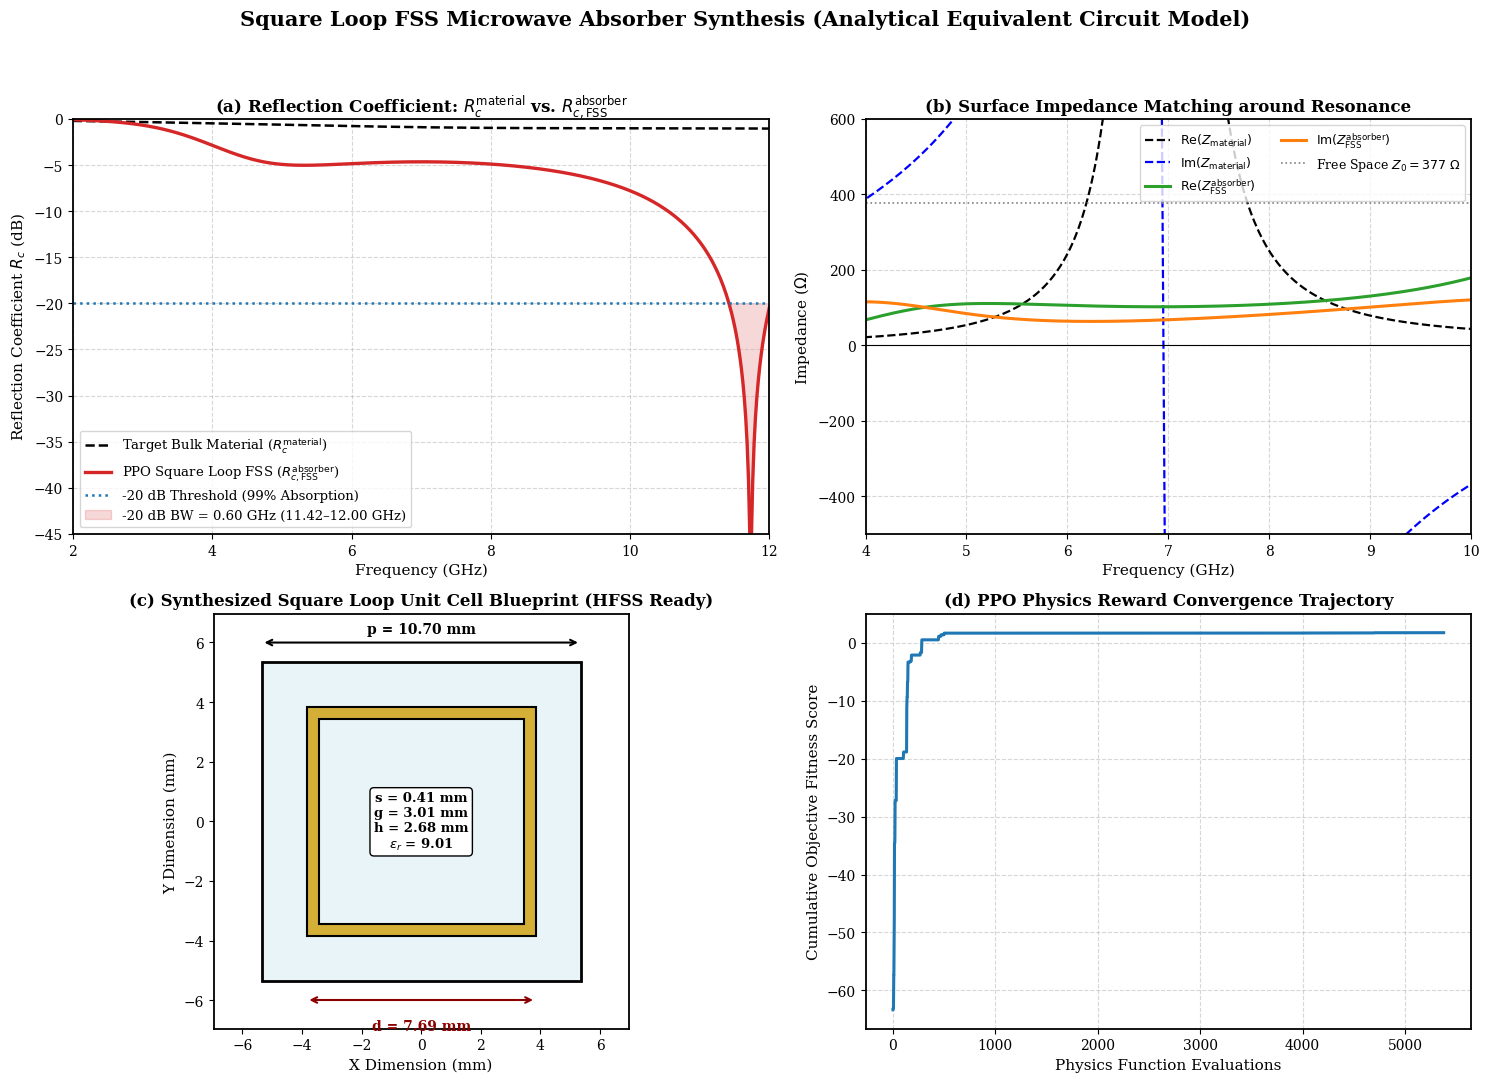

In [6]:


Z_fss_opt, Rc_fss_opt, aux_opt = SquareLoopFSSPhysics.simulate_fss_absorber(FREQ_HZ, ppo_best_params)

plt.style.use('default')
plt.rcParams['font.family'] = 'serif'
plt.rcParams['axes.linewidth'] = 1.3

fig = plt.figure(figsize=(15, 11))
fig.suptitle(
    "Square Loop FSS Microwave Absorber Synthesis (Analytical Equivalent Circuit Model)",
    fontsize=15, fontweight='bold', y=0.98
)

gs = fig.add_gridspec(2, 2, width_ratios=[1.15, 1.0], height_ratios=[1.0, 1.0])
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])

# -------------------------------------------------------------------------
# Panel (a): Frequency vs. Reflection Coefficient Rc (Page 1 & Page 2 Plot)
# -------------------------------------------------------------------------
ax1.plot(FREQ_GHZ, Rc_mat_target, 'k--', linewidth=1.8, label=r'Target Bulk Material ($R_c^{\mathrm{material}}$)')
ax1.plot(FREQ_GHZ, Rc_fss_opt, color='#d62728', linewidth=2.4, label=r'PPO Square Loop FSS ($R_{c,\mathrm{FSS}}^{\mathrm{absorber}}$)')
ax1.axhline(-20.0, color='#1f77b4', linestyle=':', linewidth=1.8, label='-20 dB Threshold (99% Absorption)')

# Shade the -20 dB bandwidth region
below_20 = Rc_fss_opt <= -20.0
if np.any(below_20):
    f_below = FREQ_GHZ[below_20]
    f_low, f_high = f_below[0], f_below[-1]
    ax1.fill_between(FREQ_GHZ, Rc_fss_opt, -20.0, where=below_20, color='#d62728', alpha=0.18,
                     label=f'-20 dB BW = {ppo_best_metrics["bw_20db_ghz"]:.2f} GHz ({f_low:.2f}–{f_high:.2f} GHz)')

ax1.set_title(r"(a) Reflection Coefficient: $R_c^{\mathrm{material}}$ vs. $R_{c,\mathrm{FSS}}^{\mathrm{absorber}}$", fontsize=12, fontweight='bold')
ax1.set_xlabel("Frequency (GHz)", fontsize=11)
ax1.set_ylabel("Reflection Coefficient $R_c$ (dB)", fontsize=11)
ax1.set_xlim([2.0, 12.0])
ax1.set_ylim([-45.0, 0.0])
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower left', fontsize=9.5)

# -------------------------------------------------------------------------
# Panel (b): Impedance Matching Verification (Z_material vs Z_FSS)
# -------------------------------------------------------------------------
ax2.plot(FREQ_GHZ, np.real(Z_mat_target), 'k--', linewidth=1.6, label=r'$\mathrm{Re}(Z_{\mathrm{material}})$')
ax2.plot(FREQ_GHZ, np.imag(Z_mat_target), 'b--', linewidth=1.6, label=r'$\mathrm{Im}(Z_{\mathrm{material}})$')
ax2.plot(FREQ_GHZ, np.real(Z_fss_opt), color='#2ca02c', linewidth=2.2, label=r'$\mathrm{Re}(Z_{\mathrm{FSS}}^{\mathrm{absorber}})$')
ax2.plot(FREQ_GHZ, np.imag(Z_fss_opt), color='#ff7f0e', linewidth=2.2, label=r'$\mathrm{Im}(Z_{\mathrm{FSS}}^{\mathrm{absorber}})$')
ax2.axhline(Z0, color='gray', linestyle=':', linewidth=1.2, label=r'Free Space $Z_0 = 377\ \Omega$')
ax2.axhline(0.0, color='black', linewidth=0.8)

ax2.set_title(r"(b) Surface Impedance Matching around Resonance", fontsize=12, fontweight='bold')
ax2.set_xlabel("Frequency (GHz)", fontsize=11)
ax2.set_ylabel(r"Impedance ($\Omega$)", fontsize=11)
ax2.set_xlim([4.0, 10.0])
ax2.set_ylim([-500, 600])
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right', fontsize=9, ncol=2)

# -------------------------------------------------------------------------
# Panel (c): 2D CAD Blueprint of Synthesized Square Loop Unit Cell
# -------------------------------------------------------------------------
p_val = ppo_best_params['p_mm']
d_val = ppo_best_params['d_mm']
s_val = ppo_best_params['s_mm']
g_val = ppo_best_params['g_mm']

ax3.set_xlim([-p_val * 0.65, p_val * 0.65])
ax3.set_ylim([-p_val * 0.65, p_val * 0.65])
ax3.set_aspect('equal')

# Substrate background (p x p)
sub_rect = patches.Rectangle((-p_val/2, -p_val/2), p_val, p_val, linewidth=2, edgecolor='black', facecolor='#e8f4f8', label='Dielectric Substrate')
ax3.add_patch(sub_rect)

# Outer metallic square (d x d)
outer_loop = patches.Rectangle((-d_val/2, -d_val/2), d_val, d_val, linewidth=1.5, edgecolor='black', facecolor='#d4af37', label='Conductive Loop (Rs)')
ax3.add_patch(outer_loop)

# Inner etched hole ((d - 2s) x (d - 2s))
inner_len = d_val - 2.0 * s_val
inner_hole = patches.Rectangle((-inner_len/2, -inner_len/2), inner_len, inner_len, linewidth=1.5, edgecolor='black', facecolor='#e8f4f8')
ax3.add_patch(inner_hole)

# Dimension annotations
ax3.annotate('', xy=(-p_val/2, p_val*0.56), xytext=(p_val/2, p_val*0.56), arrowprops=dict(arrowstyle='<->', lw=1.5))
ax3.text(0, p_val*0.58, f"p = {p_val:.2f} mm", ha='center', va='bottom', fontsize=10, fontweight='bold')

ax3.annotate('', xy=(-d_val/2, -p_val*0.56), xytext=(d_val/2, -p_val*0.56), arrowprops=dict(arrowstyle='<->', lw=1.5, color='darkred'))
ax3.text(0, -p_val*0.62, f"d = {d_val:.2f} mm", ha='center', va='top', fontsize=10, fontweight='bold', color='darkred')

ax3.text(0, 0, f"s = {s_val:.2f} mm\ng = {g_val:.2f} mm\nh = {ppo_best_params['h_mm']:.2f} mm\n" + r"$\varepsilon_r$ = " + f"{ppo_best_params['eps_r']:.2f}",
         ha='center', va='center', fontsize=9.5, fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='black'))

ax3.set_title("(c) Synthesized Square Loop Unit Cell Blueprint (HFSS Ready)", fontsize=12, fontweight='bold')
ax3.set_xlabel("X Dimension (mm)", fontsize=11)
ax3.set_ylabel("Y Dimension (mm)", fontsize=11)
ax3.grid(False)

# -------------------------------------------------------------------------
# Panel (d): PPO Convergence Curve
# -------------------------------------------------------------------------
ax4.plot(np.arange(1, len(ppo_history) + 1), ppo_history, color='#1f77b4', linewidth=2.2)
ax4.set_title("(d) PPO Physics Reward Convergence Trajectory", fontsize=12, fontweight='bold')
ax4.set_xlabel("Physics Function Evaluations", fontsize=11)
ax4.set_ylabel("Cumulative Objective Fitness Score", fontsize=11)
ax4.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("square_loop_fss_ppo_synthesis.png", dpi=300, bbox_inches='tight')
print(">> Saved figure: square_loop_fss_ppo_synthesis.png")
plt.show()

In [7]:
# =============================================================================
# CELL 7: AMORTIZED TARGET-CONDITIONED PPO POLICY (ZERO-SHOT FSS SYNTHESIS)
# =============================================================================

class AmortizedFSSPolicyNet(nn.Module):
    """
    Input: Normalized Target Resonance Frequency f_target in [5.0, 9.5] GHz
    Output: 6 Latent Continuous Variables mapped directly into constraint-safe (p, d, s, h, eps_r, Rs)
    """
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 128),
            nn.SiLU(),
            nn.Linear(128, 128),
            nn.SiLU(),
            nn.Linear(128, 6),
            nn.Sigmoid()  # Normalized [0, 1]^6
        )

    def forward(self, f_norm: torch.Tensor) -> torch.Tensor:
        return self.net(f_norm)

    @staticmethod
    def decode_to_physical(u01: torch.Tensor) -> Dict[str, torch.Tensor]:
        """Differentiable PyTorch decoding that strictly enforces p > d and d > 2s."""
        p_mm = 8.0 + u01[:, 0] * (22.0 - 8.0)
        d_mm = p_mm * (0.45 + u01[:, 1] * (0.92 - 0.45))
        s_mm = d_mm * (0.04 + u01[:, 2] * (0.38 - 0.04))
        h_mm = 1.5 + u01[:, 3] * (8.0 - 1.5)
        eps_r = 1.5 + u01[:, 4] * (10.0 - 1.5)
        Rs_ohm = 0.5 + u01[:, 5] * (15.0 - 0.5)
        return {
            'p_mm': p_mm, 'd_mm': d_mm, 's_mm': s_mm, 'g_mm': p_mm - d_mm,
            'h_mm': h_mm, 'eps_r': eps_r, 'Rs_ohm': Rs_ohm
        }


# 1. Discover anchor solutions across 5 training frequencies using PPO solver
train_freqs_ghz = [5.0, 6.0, 7.0, 8.0, 9.0]
anchor_latent_vectors = []

print(">> Building Training Anchors across 5.0 - 9.0 GHz via Physics Objective...")
for f_t in train_freqs_ghz:
    # Scale reference slab thickness inversely with target frequency to shift target dip
    scaled_mat = copy.deepcopy(ACTIVE_MATERIAL_PARAMS)
    scaled_mat['d_mat_mm'] = 3.50 * (7.0 / f_t)
    Z_m = BulkMaterialPhysics.compute_impedance(FREQ_HZ, **scaled_mat)
    Rc_m = BulkMaterialPhysics.compute_reflection_db(Z_m)

    obj_f = build_fss_physics_objective(FREQ_GHZ, FREQ_HZ, Z_m, Rc_m)
    solver_f = PPOSquareLoopSolver(obj_f, iterations=55, rollout_steps=48)
    solver_f.run(seed=SEED)
    anchor_latent_vectors.append((solver_f.env.best_u + 1.0) * 0.5)

anchor_targets_t = torch.tensor([[(f - 5.0) / 4.0] for f in train_freqs_ghz], dtype=torch.float32)
anchor_u01_t = torch.tensor(np.array(anchor_latent_vectors), dtype=torch.float32)

# 2. Train Amortized Policy Network
torch.manual_seed(SEED)
amortized_fss_policy = AmortizedFSSPolicyNet()
opt_amortized = optim.Adam(amortized_fss_policy.parameters(), lr=0.008)

for epoch in range(600):
    opt_amortized.zero_grad()
    pred_u01 = amortized_fss_policy(anchor_targets_t)
    loss = nn.functional.mse_loss(pred_u01, anchor_u01_t)
    loss.backward()
    opt_amortized.step()

# 3. Test Zero-Shot Generalization on UNSEEN Intermediate Target Frequencies
unseen_test_freqs = [5.5, 6.5, 7.5, 8.5]

print("\n" + "=" * 105)
print(f"{'ZERO-SHOT AMORTIZED PPO POLICY ON UNSEEN TARGET FREQUENCIES (1 EVALUATION)':^105}")
print("=" * 105)
hdr = f"| {'Unseen Target':^14} | {'Synthesized (p, d, g, s, h, eps_r)':^42} | {'f_res':^8} | {'Min Rc':^9} | {'-20dB BW':^9} | {'Time':^8} |"
sep = "+" + "-"*16 + "+" + "-"*44 + "+" + "-"*10 + "+" + "-"*11 + "+" + "-"*11 + "+" + "-"*10 + "+"
print(sep)
print(hdr)
print(sep)

for f_unseen in unseen_test_freqs:
    t_start = time.perf_counter()
    with torch.no_grad():
        f_norm = torch.tensor([[(f_unseen - 5.0) / 4.0]], dtype=torch.float32)
        u01_pred = amortized_fss_policy(f_norm).squeeze(0).numpy()
        u_signed = u01_pred * 2.0 - 1.0
        zero_shot_params = ppo_solver.env._latent_to_physical(u_signed)
    dt_ms = (time.perf_counter() - t_start) * 1000.0

    Z_zs, Rc_zs, _ = SquareLoopFSSPhysics.simulate_fss_absorber(FREQ_HZ, zero_shot_params)
    m_zs = SquareLoopFSSPhysics.evaluate_performance_metrics(FREQ_GHZ, Rc_zs, Z_zs, Z_mat_target)

    p_str = (
        f"p={zero_shot_params['p_mm']:.1f}, d={zero_shot_params['d_mm']:.1f}, "
        f"g={zero_shot_params['g_mm']:.1f}, s={zero_shot_params['s_mm']:.2f}, "
        f"h={zero_shot_params['h_mm']:.2f}, er={zero_shot_params['eps_r']:.2f}"
    )
    print(
        f"| {f_unseen:>9.1f} GHz  | {p_str:<42} | {m_zs['f_res_ghz']:>5.2f}GHz | "
        f"{m_zs['min_rc_db']:>6.2f} dB | {m_zs['bw_20db_ghz']:>6.2f}GHz | {dt_ms:>5.2f} ms |"
    )

print(sep)

>> Building Training Anchors across 5.0 - 9.0 GHz via Physics Objective...

               ZERO-SHOT AMORTIZED PPO POLICY ON UNSEEN TARGET FREQUENCIES (1 EVALUATION)                
+----------------+--------------------------------------------+----------+-----------+-----------+----------+
| Unseen Target  |     Synthesized (p, d, g, s, h, eps_r)     |  f_res   |  Min Rc   | -20dB BW  |   Time   |
+----------------+--------------------------------------------+----------+-----------+-----------+----------+
|       5.5 GHz  | p=10.7, d=6.1, g=4.7, s=0.28, h=1.82, er=2.19 | 12.00GHz |  -6.61 dB |   0.00GHz |  0.69 ms |
|       6.5 GHz  | p=11.8, d=6.3, g=5.5, s=0.32, h=1.91, er=1.50 | 12.00GHz |  -1.92 dB |   0.00GHz |  0.06 ms |
|       7.5 GHz  | p=20.4, d=9.8, g=10.5, s=1.50, h=1.51, er=1.50 | 12.00GHz |  -4.85 dB |   0.00GHz |  0.06 ms |
|       8.5 GHz  | p=20.2, d=9.8, g=10.4, s=0.49, h=1.64, er=1.50 | 11.14GHz |  -7.74 dB |   0.00GHz |  0.05 ms |
+----------------+----------------

In [8]:
# =============================================================================
# CELL 8: ANSYS HFSS 3D MODELER ENTRY SHEET FOR SYNTHESIZED SQUARE LOOP
# =============================================================================

p = ppo_best_params['p_mm']
d = ppo_best_params['d_mm']
s = ppo_best_params['s_mm']
g = ppo_best_params['g_mm']
h = ppo_best_params['h_mm']
eps_r = ppo_best_params['eps_r']
Rs = ppo_best_params['Rs_ohm']
inner_d = d - 2.0 * s

print("\n" + "#" * 88)
print(f"{'ANSYS HFSS STEP-BY-STEP DIMENSION SHEET (UNITS: mm)':^88}")
print("#" * 88)
print(f"""
1. SUBSTRATE BOX (Draw -> Box):
   - Position : ({-p/2:.4f}, {-p/2:.4f}, 0.0)
   - XSize    : {p:.4f} mm
   - YSize    : {p:.4f} mm
   - ZSize    : {h:.4f} mm
   - Material : Custom Dielectric (Relative Permittivity = {eps_r:.4f}, Loss Tangent = 0.002)

2. GROUND PLANE (Select Bottom Face of Substrate at Z = 0):
   - Right-Click Face -> Assign Boundary -> Perfect E (PEC Ground Backing)

3. SQUARE LOOP FSS ON TOP FACE (Z = {h:.4f} mm):
   - Step 3a (Outer Square): Draw Rectangle at Position ({-d/2:.4f}, {-d/2:.4f}, {h:.4f})
                             with XSize = {d:.4f} mm, YSize = {d:.4f} mm
   - Step 3b (Inner Cutout): Draw Rectangle at Position ({-inner_d/2:.4f}, {-inner_d/2:.4f}, {h:.4f})
                             with XSize = {inner_d:.4f} mm, YSize = {inner_d:.4f} mm
   - Step 3c (Boolean Subtract): Select Outer Square, subtract Inner Cutout -> Forms Square Loop!
   - Step 3d (Assign Sheet Impedance): Select Square Loop -> Assign Boundary -> Impedance
                             Resistance = {Rs:.2f} Ohms/sq, Reactance = 0 Ohms/sq

4. AIR BOX & FLOQUET PORT (Draw -> Box):
   - Position : ({-p/2:.4f}, {-p/2:.4f}, 0.0)
   - XSize    : {p:.4f} mm
   - YSize    : {p:.4f} mm
   - ZSize    : {h + 25.0:.4f} mm (Extends 25 mm above the FSS sheet)
   - Side Walls (X and Y faces): Assign Master / Slave (or Primary / Secondary) Periodic Boundaries
   - Top Face (Z = {h + 25.0:.4f} mm): Assign Excitation -> Floquet Port (De-embed distance = 25.0 mm)

5. FREQUENCY SWEEP SETUP:
   - Solution Frequency : {ppo_best_metrics['f_res_ghz']:.2f} GHz
   - Interpolating Sweep: 2.0 GHz to 12.0 GHz (500 points)
   - Plot Output        : Rectangular Plot -> S(FloquetPort1:1, FloquetPort1:1) in dB (Matches Rc_FSS!)
""")
print("#" * 88)


########################################################################################
                  ANSYS HFSS STEP-BY-STEP DIMENSION SHEET (UNITS: mm)                   
########################################################################################

1. SUBSTRATE BOX (Draw -> Box):
   - Position : (-5.3524, -5.3524, 0.0)
   - XSize    : 10.7048 mm
   - YSize    : 10.7048 mm
   - ZSize    : 2.6793 mm
   - Material : Custom Dielectric (Relative Permittivity = 9.0087, Loss Tangent = 0.002)

2. GROUND PLANE (Select Bottom Face of Substrate at Z = 0):
   - Right-Click Face -> Assign Boundary -> Perfect E (PEC Ground Backing)

3. SQUARE LOOP FSS ON TOP FACE (Z = 2.6793 mm):
   - Step 3a (Outer Square): Draw Rectangle at Position (-3.8454, -3.8454, 2.6793)
                             with XSize = 7.6909 mm, YSize = 7.6909 mm
   - Step 3b (Inner Cutout): Draw Rectangle at Position (-3.4402, -3.4402, 2.6793)
                             with XSize = 6.8803 mm, YSize = 6.8803 